<a href="https://colab.research.google.com/github/poojavjpy/ML-Data-Analytics/blob/main/sentiment_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



## ***Sentiment Analysis using Machine Learning***



# A sentiment analysis model using the Multinomial Naive Bayes algorithm and Bag of Words feature extraction is implemented to classify text into positive and negative sentiments.

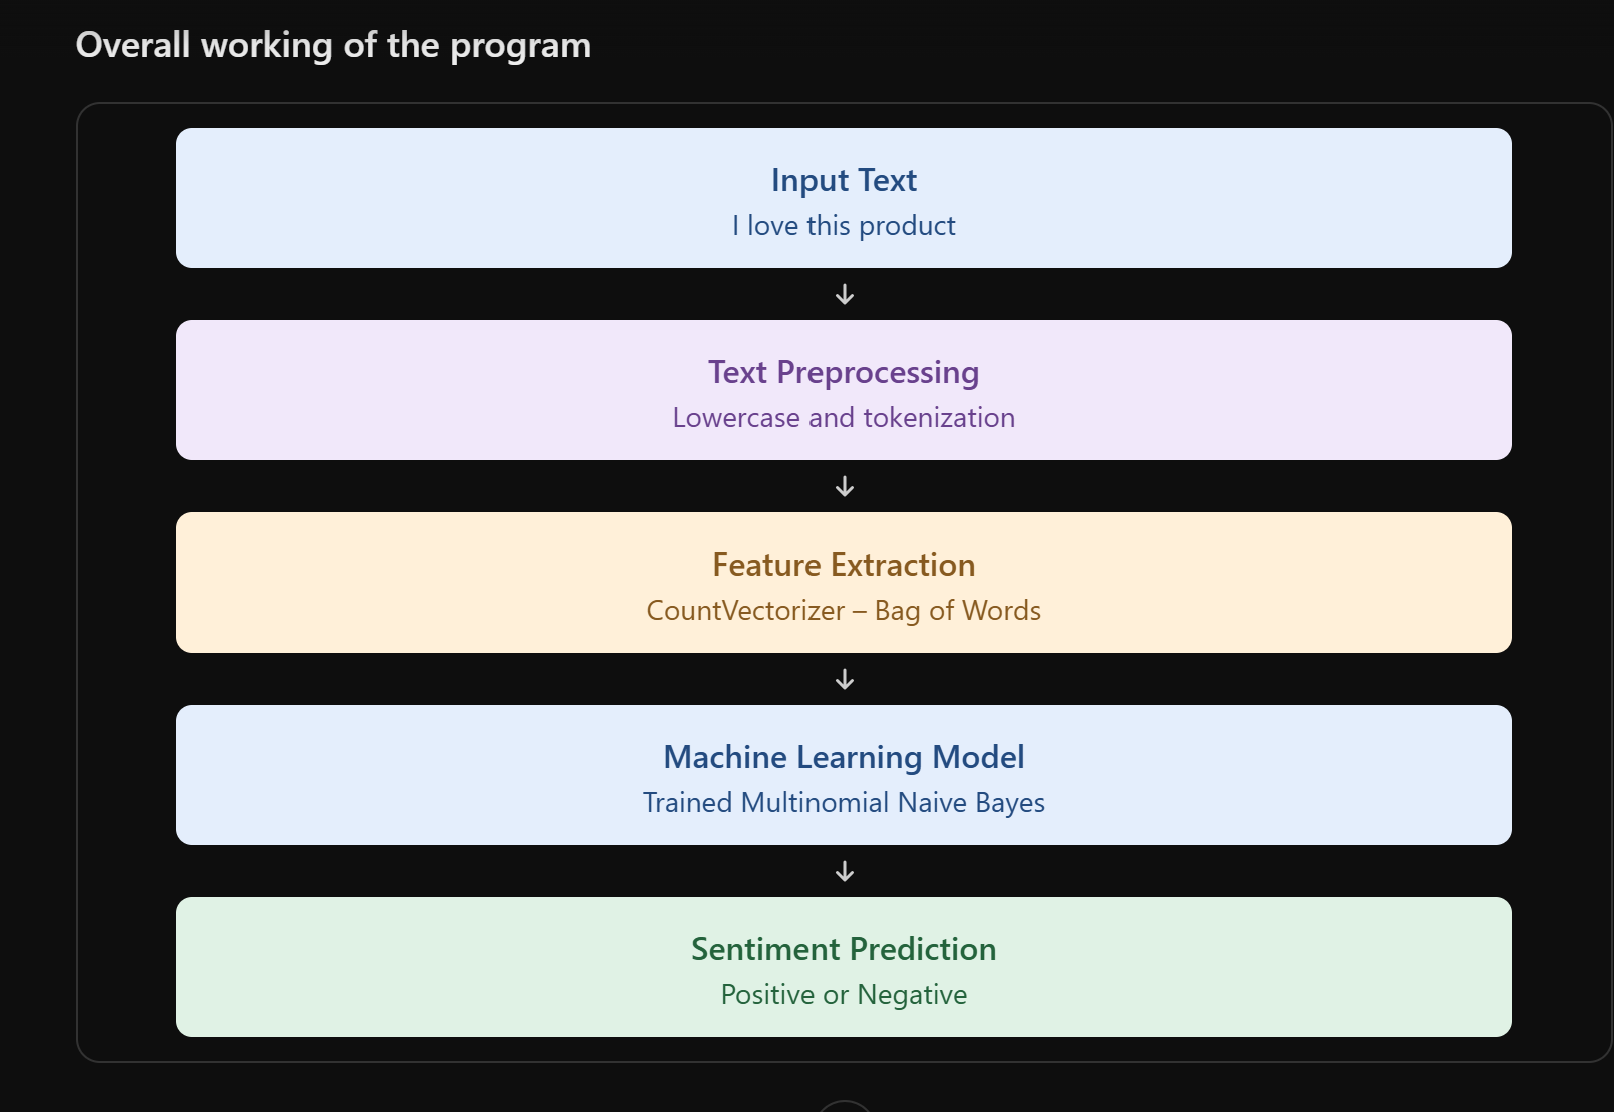

In [1]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

In [2]:
data = {
    'Review': [
        'I love this product',
        'This is an amazing movie',
        'Excellent service',
        'I am very happy',
        'The food was delicious',
        'Wonderful experience',
        'This product is fantastic',
        'I really enjoyed the movie',
        'Very good quality',
        'I love the service',
        'I hate this product',
        'This movie is terrible',
        'Very bad service',
        'I am disappointed',
        'The food was horrible',
        'Worst experience ever',
        'This product is useless',
        'I dislike this movie',
        'Very poor quality',
        'I hate the service'
    ],
    'Sentiment': ['Positive'] * 10 + ['Negative'] * 10
}

df = pd.DataFrame(data)
display(df)

,Review,Sentiment
0,I love this product,Positive
1,This is an amazing movie,Positive
2,Excellent service,Positive
3,I am very happy,Positive
4,The food was delicious,Positive
5,Wonderful experience,Positive
6,This product is fantastic,Positive
7,I really enjoyed the movie,Positive
8,Very good quality,Positive
9,I love the service,Positive


In [3]:
X = df['Review']
y = df['Sentiment']

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 16
Testing samples: 4


In [5]:
vectorizer = CountVectorizer()

X_train_vector = vectorizer.fit_transform(X_train)
X_test_vector = vectorizer.transform(X_test)

print("Vocabulary:")
print(vectorizer.get_feature_names_out())

print("\nNumerical representation:")
print(X_train_vector.toarray())

Vocabulary:
['am' 'amazing' 'an' 'bad' 'delicious' 'dislike' 'enjoyed' 'ever'
 'experience' 'food' 'good' 'happy' 'hate' 'horrible' 'is' 'love' 'movie'
 'poor' 'product' 'quality' 'really' 'service' 'terrible' 'the' 'this'
 'very' 'was' 'wonderful' 'worst']

Numerical representation:
[[0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0]
 [0 1 1 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 0]
 [1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 1 0 0 0 0 0]
 [0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 0 0 0 0 0]
 [0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 

In [6]:
model = MultinomialNB()

model.fit(X_train_vector, y_train)

print("Model trained successfully!")

Model trained successfully!


In [7]:
y_pred = model.predict(X_test_vector)

result = pd.DataFrame({
    'Review': X_test,
    'Actual Sentiment': y_test,
    'Predicted Sentiment': y_pred
})

display(result)

,Review,Actual Sentiment,Predicted Sentiment
16,This product is useless,Negative,Negative
13,I am disappointed,Negative,Positive
2,Excellent service,Positive,Negative
6,This product is fantastic,Positive,Negative


In [8]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.25

Classification Report:
              precision    recall  f1-score   support

    Negative       0.33      0.50      0.40         2
    Positive       0.00      0.00      0.00         2

    accuracy                           0.25         4
   macro avg       0.17      0.25      0.20         4
weighted avg       0.17      0.25      0.20         4



In [9]:
review = input("Enter your review: ")

review_vector = vectorizer.transform([review])

prediction = model.predict(review_vector)

print("Predicted Sentiment:", prediction[0])

Enter your review: this is good
Predicted Sentiment: Positive


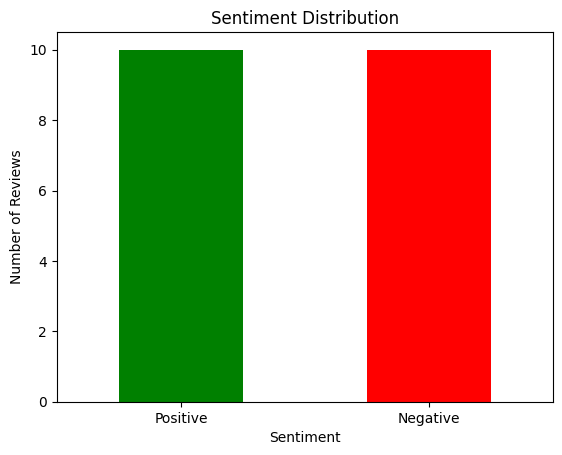

In [10]:
import matplotlib.pyplot as plt

df['Sentiment'].value_counts().plot(
    kind='bar',
    color=['green', 'red']
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.show()

Lab exercise questions
1. Add five positive and five negative reviews to the dataset and retrain the model.
2. Change the training and testing ratio to 70:30 and compare the accuracy.
3. Replace CountVectorizer with TfidfVectorizer.
4. Replace Naive Bayes with Logistic Regression and compare the performance.
5. Test the model using the sentence "This movie is not good." Observe whether the prediction is correct and explain why.